# Previous-close signals, next-open trades

**Yes: the original backtest uses adjusted close prices for both signals and execution.** Here we estimate adjusted opens with:

`Adjusted Open = Open × (Adj Close / Close)`

This applies the same daily adjustment factor to the open and close. It puts both on a consistent split/dividend-adjusted scale; it does not mean we can actually transact at that adjusted price. Holdings and profit are synthetic adjusted-price accounting, as in the baseline, rather than a broker ledger with explicit dividends and corporate actions.

We reuse the original winning parameters, selected pairs, formation models, and equal-pair allocation rule. We do not search for a new winner or load holdout observations.

**This is an execution experiment, not a new signal strategy.** A closing signal triggers an order for the following session's open. We do not use that following close to decide whether to enter. The adjustment factor normalizes historical prices; it is not a predictive input at the open.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RUN_ID = None  # Set explicitly if more than one saved search exists.
base = ROOT / 'outputs' / 'joint_grid_search_zero_cost'
runs = sorted(p.parent for p in base.glob('*/grid_summary.csv'))
if RUN_ID is None:
    if len(runs) != 1:
        raise ValueError(f'Set RUN_ID to one of {[p.name for p in runs]}')
    run = runs[0]
else:
    run = base / RUN_ID
summary = pd.read_csv(run / 'grid_summary.csv')
complete = summary.loc[summary['Status'].eq('complete') & np.isfinite(summary['Sharpe Ratio'])]
if complete.empty:
    raise ValueError('No completed strategy with finite Sharpe ratio.')
winner = complete.sort_values('Sharpe Ratio', ascending=False, kind='stable').iloc[0]
folder = run / Path(winner['Output Folder']).name
params = json.loads((folder / 'parameters.json').read_text())
assert params['cost_bps_per_leg'] == 0
initial = params['initial_capital']
print(f'Run: {run.name}; completed combinations: {len(complete)} / {len(summary)}')
print('Selected parameters:', params)
portfolio = pd.read_csv(folder / 'portfolio_daily.csv', parse_dates=['Date']).set_index('Date').sort_index()
trades = pd.read_csv(folder / 'trades.csv')
for col in ['Entry Signal Date', 'Entry Date', 'Exit Signal Date', 'Exit Date']:
    trades[col] = pd.to_datetime(trades[col])
assert portfolio.index.is_unique and portfolio.index.max() < pd.Timestamp('2023-08-25')
assert trades[['Entry Date', 'Exit Date']].notna().all().all()
assert trades['Exit Date'].ge(trades['Entry Date']).all()
trades['Entry Year'] = trades['Entry Date'].dt.year
trades['Exit Year'] = trades['Exit Date'].dt.year
trades['Pair'] = [' / '.join(sorted((a, b))) for a, b in zip(trades.A, trades.B)]

Run: cb64c19613e1e11beb71; completed combinations: 1248 / 1248
Selected parameters: {'formation_months': 18, 'trading_months': 6, 'correlation_threshold': 0.8, 'eg_significance': 0.01, 'entry_z': 1.5, 'exit_z': 0.5, 'stop_z': 4.0, 'run_id': 'cb64c19613e1e11beb71', 'cost_bps_per_leg': 0.0, 'initial_capital': 100000.0}


## Run the comparison

- Entry, mean-reversion exits, and stop-loss exits use the **next session's adjusted open**.
- We value open holdings at each day's adjusted close, including overnight and intraday changes.
- The pre-scheduled trading-window liquidation stays at the **last session's close**, matching the original backtest. No new positions open on that final session.
- Signals are not rechecked or cancelled at the opening price. That would be a separate experiment.
- This first comparison keeps the original **zero costs**, including zero borrowing costs and slippage, to isolate execution timing. Both stocks filling at the recorded open is an approximation.

Missing or invalid required prices stop the calculation; we do not silently drop pairs. The code also reruns the original next-close backtest and checks that it reproduces the saved portfolio before comparing results.

In [2]:
import sys
from functools import lru_cache
sys.path.insert(0, str(ROOT / 'src'))
from joint_grid_search import (read_training_series, backtest_pair, combine_accounts,
                               performance_metrics, HOLDOUT_START, DATA_START)
from next_open_backtest import adjusted_open, backtest_pair_next_open
from risk_free import load_treasury_yields

selected = pd.read_csv(folder / 'selected_pairs.csv')
windows = pd.read_csv(folder / 'window_summary.csv')
for col in ['Formation Start', 'Trading Start', 'Trading End Exclusive']:
    windows[col] = pd.to_datetime(windows[col])
yields = load_treasury_yields(ROOT / 'data/risk_free/DGS3MO.csv')

@lru_cache(maxsize=None)
def training_bars(ticker):
    # Date gate before interpreting any prices; never use holdout observations.
    frame = pd.read_csv(ROOT / 'data/historical' / f'{ticker}.csv',
                        usecols=['Date', 'Open', 'Close', 'Adj Close'])
    frame['Date'] = pd.to_datetime(frame['Date'])
    frame = frame.loc[frame['Date'].ge(DATA_START) & frame['Date'].lt(HOLDOUT_START)].set_index('Date').sort_index()
    assert frame.index.is_unique
    # Only selected trading sessions are validated below.
    return frame

initial_capital = float(params['initial_capital'])
capital = {'Next close': initial_capital, 'Next open': initial_capital}
daily_parts = {name: [] for name in capital}
trade_parts = {name: [] for name in capital}
window_rows = []
pair_daily_parts = []
price_audit = []
thresholds = {name: params[name] for name in ['entry_z', 'exit_z', 'stop_z']}
for _, window in windows.iterrows():
    number = int(window['Window'])
    dates = portfolio.index[(portfolio.index >= window['Trading Start']) &
                            (portfolio.index < window['Trading End Exclusive'])]
    assert len(dates) and dates.max() < HOLDOUT_START
    chosen = selected.loc[selected['Window'].eq(number)]
    tickers = sorted(set(chosen['A']) | set(chosen['B']))
    closes, opens = {}, {}
    for ticker in tickers:
        bars = training_bars(ticker).reindex(dates)
        closes[ticker] = pd.to_numeric(bars['Adj Close'], errors='coerce')
        opens[ticker] = adjusted_open(bars)
        price_audit.append({'Window': number, 'Ticker': ticker, 'Sessions': len(bars),
                            'Minimum adjustment factor': (pd.to_numeric(bars['Adj Close']) / pd.to_numeric(bars['Close'])).min(),
                            'Maximum adjustment factor': (pd.to_numeric(bars['Adj Close']) / pd.to_numeric(bars['Close'])).max()})
    closes, opens = pd.DataFrame(closes, index=dates), pd.DataFrame(opens, index=dates)
    accounts = {name: [] for name in capital}
    window_trades = {name: [] for name in capital}
    for _, pair in chosen.iterrows():
        formation = pd.DataFrame({ticker: read_training_series(
            ROOT / 'data/Filter_historical' / f'{ticker}.csv',
            start=window['Formation Start'], end=window['Trading Start']) for ticker in [pair['A'], pair['B']]})
        assert not formation.empty and formation.iloc[-1].notna().all()
        formation_last = formation.iloc[-1]
        for mode in capital:
            allocation = capital[mode] / len(chosen)
            if mode == 'Next close':
                daily, result = backtest_pair(pair, closes, formation_last, allocation,
                                             params['cost_bps_per_leg'], **thresholds)
            else:
                daily, result = backtest_pair_next_open(pair, closes, opens, formation_last, allocation,
                                                       params['cost_bps_per_leg'], **thresholds)
                pair_daily_parts.append(daily.assign(Window=number, A=pair['A'], B=pair['B']))
                result['Beta'] = pair['Beta']
                result['Spread Mean'] = pair['Spread Mean']
                result['Spread Std'] = pair['Spread Std']
                for side in ['Entry', 'Exit']:
                    fill_frame = opens.copy()
                    fill_frame.iloc[-1] = closes.iloc[-1]
                    for leg in ['A', 'B']:
                        result[f'{side} Adjusted Price {leg}'] = fill_frame[pair[leg]].reindex(pd.to_datetime(result[f'{side} Date'])).to_numpy()
            accounts[mode].append(daily)
            window_trades[mode].append(result.assign(Window=number))
    for mode in capital:
        combined = combine_accounts(accounts[mode], dates, capital[mode])
        result = pd.concat(window_trades[mode], ignore_index=True) if window_trades[mode] else trades.iloc[:0].copy()
        np.testing.assert_allclose(combined['Equity'].iloc[-1] - capital[mode], result['Net P/L ($)'].sum(), atol=1e-6)
        window_rows.append({'Execution': mode, 'Window': number, 'Initial Capital': capital[mode],
                            **performance_metrics(combined, result, capital[mode], yields)})
        capital[mode] = float(combined['Equity'].iloc[-1])
        daily_parts[mode].append(combined.assign(Window=number))
        trade_parts[mode].append(result)
    print(f'Completed window {number} / {len(windows)}')

portfolios = {mode: pd.concat(parts) for mode, parts in daily_parts.items()}
trade_results = {mode: pd.concat(parts, ignore_index=True) for mode, parts in trade_parts.items()}
for mode, daily in portfolios.items():
    assert daily.index.equals(portfolio.index)
    np.testing.assert_allclose(initial_capital * (1 + daily['Net Return']).cumprod(), daily['Equity'], rtol=1e-9)
    np.testing.assert_allclose(daily['Equity'].iloc[-1] - initial_capital,
                               trade_results[mode]['Net P/L ($)'].sum(), atol=1e-6)
    assert (pd.to_datetime(trade_results[mode]['Entry Signal Date']) < pd.to_datetime(trade_results[mode]['Entry Date'])).all()
np.testing.assert_allclose(portfolios['Next close']['Equity'], portfolio['Equity'], rtol=1e-9)
assert len(trade_results['Next close']) == len(trades)
comparison = pd.DataFrame({mode: performance_metrics(daily, trade_results[mode], initial_capital, yields)
                           for mode, daily in portfolios.items()}).T
np.testing.assert_allclose(comparison.loc['Next close', 'Sharpe Ratio'], winner['Sharpe Ratio'], atol=1e-9)
print('Original portfolio reproduced; both execution variants reconcile to trade profits.')

Completed window 1 / 15


Completed window 2 / 15
Completed window 3 / 15


Completed window 4 / 15


Completed window 5 / 15
Completed window 6 / 15


Completed window 7 / 15


Completed window 8 / 15


... (2 outputs left out)

Completed window 11 / 15


Completed window 12 / 15
Completed window 13 / 15


Completed window 14 / 15


Completed window 15 / 15
Original portfolio reproduced; both execution variants reconcile to trade profits.


## Did next-open execution help?

Compare Sharpe, total return, volatility, and maximum drawdown together. A higher return alone does not mean better risk-adjusted performance.

Sharpe uses the same definition as earlier notebooks: annual compounded growth minus the Treasury benchmark, divided by annualized daily volatility. These are development-sample results, before costs; a better result here needs later validation.

,Sharpe Ratio,Cumulative Return,Annualized Return,Annualized Volatility,Maximum Drawdown,Number of Trades,Win Rate
Next close,0.359,18.61%,2.42%,2.48%,3.50%,212,63.2%
Next open,0.158,14.63%,1.93%,2.55%,3.79%,212,66.0%


,Next close,Next open
Year,,
2016,-1.04%,-1.11%
2017,1.64%,1.47%
2018,2.15%,1.83%
2019,0.40%,0.51%
2020,5.46%,3.62%
2021,6.40%,5.16%
2022,5.45%,5.24%
2023,-2.81%,-2.68%


First and last calendar years are partial.


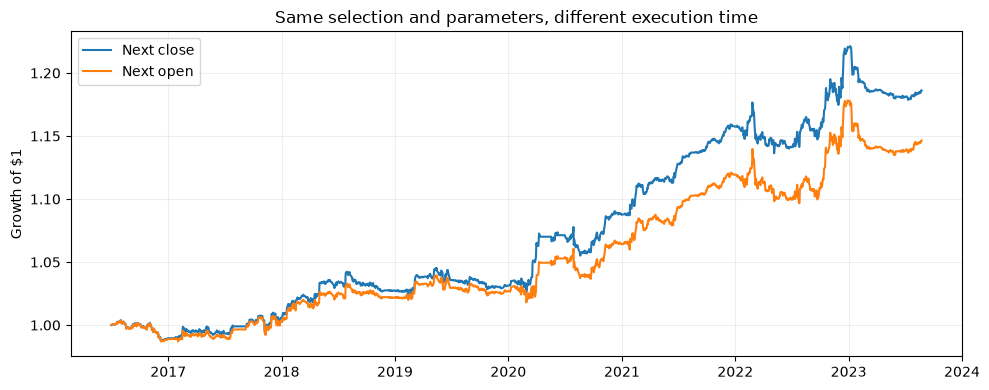

In [3]:
columns = ['Sharpe Ratio', 'Cumulative Return', 'Annualized Return', 'Annualized Volatility',
           'Maximum Drawdown', 'Number of Trades', 'Win Rate']
display(comparison[columns].style.format({
    'Sharpe Ratio': '{:.3f}', 'Cumulative Return': '{:.2%}', 'Annualized Return': '{:.2%}',
    'Annualized Volatility': '{:.2%}', 'Maximum Drawdown': '{:.2%}',
    'Number of Trades': '{:.0f}', 'Win Rate': '{:.1%}'}))
annual_returns = pd.DataFrame({mode: (1 + daily['Net Return']).groupby(daily.index.year).prod() - 1
                               for mode, daily in portfolios.items()})
annual_returns.index.name = 'Year'
display(annual_returns.style.format('{:.2%}'))
print('First and last calendar years are partial.')
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 4))
for mode, daily in portfolios.items():
    ax.plot(daily.index, daily['Equity'] / initial_capital, label=mode)
ax.set_title('Same selection and parameters, different execution time')
ax.set_ylabel('Growth of $1'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); plt.show()

## Save the experiment

Results go into a separate output folder. The original backtest and its saved trades remain unchanged.

The adjusted-open estimate is suitable for this comparison under the daily adjustment convention. A production simulation would also need actual tradable prices, corporate-action cash flows, borrowing availability, and realistic execution costs. Applying an adjustment factor is not a guarantee of an opening fill.

In [4]:
out = ROOT / 'outputs' / 'next_open_execution_zero_cost' / run.name / folder.name
out.mkdir(parents=True, exist_ok=True)
comparison.to_csv(out / 'execution_comparison.csv')
annual_returns.to_csv(out / 'annual_returns.csv')
pd.DataFrame(window_rows).to_csv(out / 'window_comparison.csv', index=False)
pd.DataFrame(price_audit).to_csv(out / 'adjustment_audit.csv', index=False)
portfolios['Next open'].to_csv(out / 'portfolio_daily.csv')
trade_results['Next open'].to_csv(out / 'trades.csv', index=False)
pd.concat(pair_daily_parts).to_csv(out / 'pair_daily.csv.gz', compression='gzip')
selected.to_csv(out / 'selected_pairs.csv', index=False)
fig.savefig(out / 'execution_comparison.png', dpi=160, bbox_inches='tight')
(out / 'experiment_manifest.json').write_text(json.dumps({
    'source_run': run.name, 'source_parameter_folder': folder.name, 'parameters': params,
    'adjusted_open': 'Open * (Adj Close / Close)',
    'signal': 'Previous adjusted close; no opening revalidation',
    'execution': 'Next session adjusted open, except scheduled final-window close liquidation',
    'accounting': 'Synthetic adjusted holdings; daily adjusted-close valuation; no separate dividends',
    'costs': 'Original zero-cost baseline; no borrowing fees or slippage',
    'selection': 'Reuse saved winning pairs and frozen formation models; no new parameter search',
    'dates': [str(portfolio.index.min().date()), str(portfolio.index.max().date())],
    'holdout_loaded': False
}, indent=2))
print(f'Saved comparison and next-open backtest to {out.relative_to(ROOT)}')

Saved comparison and next-open backtest to outputs/next_open_execution_zero_cost/cb64c19613e1e11beb71/formation_months_18_trading_months_6_correlation_threshold_0.8_eg_significance_0.01_entry_z_1.5_exit_z_0.5_stop_z_4
